In [1]:

# Import required libraries

import re
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from matplotlib.patches import Circle, FancyArrowPatch

print("FLA Project Setup Completed Successfully!")



FLA Project Setup Completed Successfully!


In [2]:

# DFA Transition Table - Date Format Validator

date_transitions = {
    "q0":  {"D": "q1",  "H": "qT", "O": "qT"},
    "q1":  {"D": "q2",  "H": "qT", "O": "qT"},
    "q2":  {"D": "qT", "H": "q3",  "O": "qT"},
    "q3":  {"D": "q4",  "H": "qT", "O": "qT"},
    "q4":  {"D": "q5",  "H": "qT", "O": "qT"},
    "q5":  {"D": "qT", "H": "q6",  "O": "qT"},
    "q6":  {"D": "q7",  "H": "qT", "O": "qT"},
    "q7":  {"D": "q8",  "H": "qT", "O": "qT"},
    "q8":  {"D": "q9",  "H": "qT", "O": "qT"},
    "q9":  {"D": "q10", "H": "qT", "O": "qT"},
    "q10": {"D": "qT", "H": "qT", "O": "qT"},
    "qT":  {"D": "qT", "H": "qT", "O": "qT"}
}

date_table = pd.DataFrame.from_dict(
    date_transitions,
    orient="index"
)

date_table.index.name = "Current State"
date_table.columns = ["Digit (D)", "Hyphen (H)", "Other (O)"]

display(date_table)


,Digit (D),Hyphen (H),Other (O)
Current State,,,
q0,q1,qT,qT
q1,q2,qT,qT
q2,qT,q3,qT
q3,q4,qT,qT
q4,q5,qT,qT
q5,qT,q6,qT
q6,q7,qT,qT
q7,q8,qT,qT
q8,q9,qT,qT


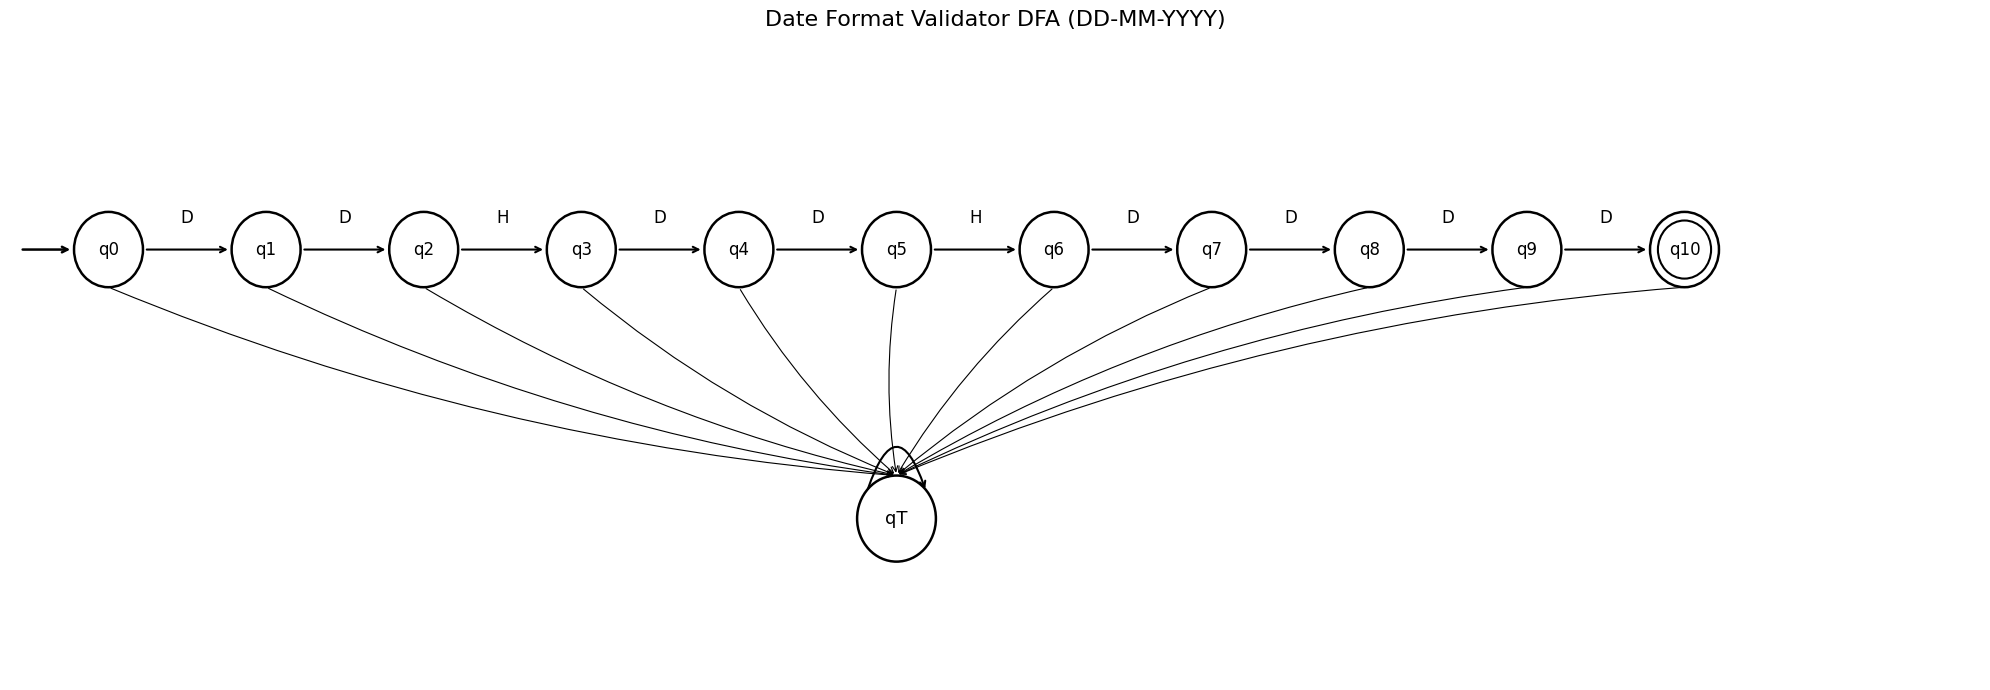

In [3]:

# Black and White DFA Diagram - Date Format Validator

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(20, 7))

ax.set_xlim(-1, 19)
ax.set_ylim(-3, 3)
ax.axis("off")

# State positions
states = [f"q{i}" for i in range(11)]
positions = {f"q{i}": (i * 1.6, 1) for i in range(11)}

# Draw states
for state, (x, y) in positions.items():
    ax.add_patch(Circle((x, y), 0.35, fill=False,
                        color="black", linewidth=1.8))

    # Double circle for final state
    if state == "q10":
        ax.add_patch(Circle((x, y), 0.27, fill=False,
                            color="black", linewidth=1.5))

    ax.text(x, y, state, ha="center", va="center", fontsize=12)

# Start arrow
ax.annotate("", xy=(-0.36, 1), xytext=(-0.9, 1),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.8))

# Transition labels
labels = ["D", "D", "H", "D", "D", "H", "D", "D", "D", "D"]

# Draw main transitions
for i in range(10):
    x1 = positions[f"q{i}"][0] + 0.36
    x2 = positions[f"q{i+1}"][0] - 0.36

    ax.annotate("", xy=(x2, 1), xytext=(x1, 1),
                arrowprops=dict(arrowstyle="->", color="black", lw=1.5))

    ax.text((x1+x2)/2, 1.25, labels[i],
            ha="center", fontsize=12)

# Trap state
trap_x, trap_y = 8, -1.5

ax.add_patch(Circle((trap_x, trap_y), 0.4,
                    fill=False, color="black", linewidth=1.8))

ax.text(trap_x, trap_y, "qT", ha="center",
        va="center", fontsize=13)

# Invalid transitions from each state
for i in range(11):
    x = positions[f"q{i}"][0]

    ax.annotate(
        "",
        xy=(trap_x, trap_y + 0.4),
        xytext=(x, 0.65),
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=0.8,
            connectionstyle="arc3,rad=0.08"
        )
    )

# Trap state self-loop
ax.annotate(
    "",
    xy=(trap_x + 0.3, trap_y + 0.25),
    xytext=(trap_x - 0.3, trap_y + 0.25),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-1.5",
        color="black",
        lw=1.5
    )
)

plt.title("Date Format Validator DFA (DD-MM-YYYY)",
          fontsize=16)

plt.tight_layout()
plt.show()


In [4]:

# Date Format Validator using DFA concepts

import re
from datetime import datetime

def date_validator(date):

    # Step 1: Check the DFA input pattern
    pattern = r"^[0-9]{2}-[0-9]{2}-[0-9]{4}$"

    if not re.fullmatch(pattern, date):
        return False

    # Step 2: Check actual calendar validity
    try:
        datetime.strptime(date, "%d-%m-%Y")
        return True

    except ValueError:
        return False


# Test the Date Validator
print("DATE FORMAT VALIDATOR")
print("---------------------")

date = input("Enter date (DD-MM-YYYY): ")

if date_validator(date):
    print("Accepted: Valid Date")
else:
    print("Rejected: Invalid Date")


DATE FORMAT VALIDATOR
---------------------
Enter date (DD-MM-YYYY): 12-14-2007
Rejected: Invalid Date


In [5]:

# Testing valid and invalid dates

date_test_cases = [
    "11-11-2026",
    "29-02-2024",
    "31-02-2026",
    "29-02-2029",
    "12-98-2026",
    "1-01-2026"
]

print("DATE VALIDATION TEST RESULTS")
print("----------------------------")

for date in date_test_cases:
    if date_validator(date):
        print(date, "-> Accepted")
    else:
        print(date, "-> Rejected")


DATE VALIDATION TEST RESULTS
----------------------------
11-11-2026 -> Accepted
29-02-2024 -> Accepted
31-02-2026 -> Rejected
29-02-2029 -> Rejected
12-98-2026 -> Rejected
1-01-2026 -> Rejected


OTP Validator

In [6]:
otp_transitions = {
    "q0": {"D": "q1", "O": "qT"},
    "q1": {"D": "q2", "O": "qT"},
    "q2": {"D": "q3", "O": "qT"},
    "q3": {"D": "q4", "O": "qT"},
    "q4": {"D": "q5", "O": "qT"},
    "q5": {"D": "q6", "O": "qT"},
    "q6": {"D": "qT", "O": "qT"},
    "qT": {"D": "qT", "O": "qT"}
}

otp_table = pd.DataFrame.from_dict(
    otp_transitions,
    orient="index"
)

print("OTP VALIDATOR - DFA TRANSITION TABLE")
display(otp_table)

OTP VALIDATOR - DFA TRANSITION TABLE


,D,O
q0,q1,qT
q1,q2,qT
q2,q3,qT
q3,q4,qT
q4,q5,qT
q5,q6,qT
q6,qT,qT
qT,qT,qT


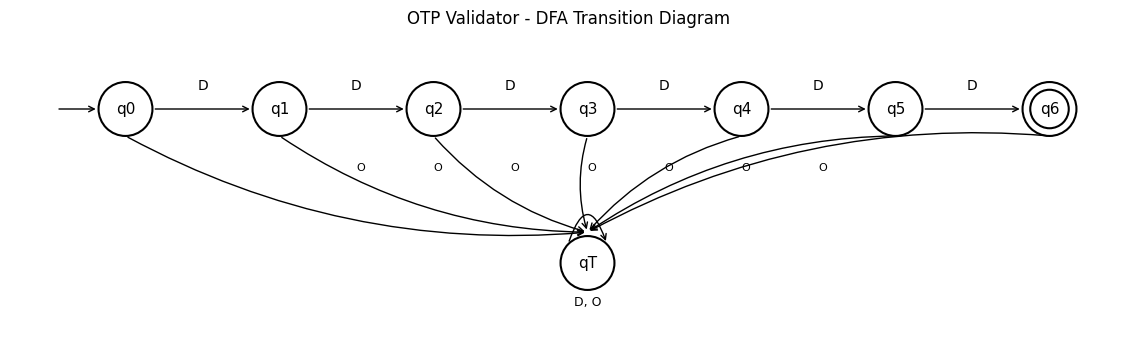

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(15, 4))

states = {
    "q0": (1, 2),
    "q1": (3, 2),
    "q2": (5, 2),
    "q3": (7, 2),
    "q4": (9, 2),
    "q5": (11, 2),
    "q6": (13, 2),
    "qT": (7, 0)
}

# Draw states
for state, (x, y) in states.items():
    if state == "q6":
        ax.add_patch(Circle((x, y), 0.35, fill=False, color="black", linewidth=1.5))
        ax.add_patch(Circle((x, y), 0.25, fill=False, color="black", linewidth=1.5))
    else:
        ax.add_patch(Circle((x, y), 0.35, fill=False, color="black", linewidth=1.5))

    ax.text(x, y, state, ha="center", va="center", fontsize=11)

# Initial arrow
ax.annotate("", xy=(0.65, 2), xytext=(0.1, 2),
            arrowprops=dict(arrowstyle="->", color="black"))

# Main transitions
for i in range(6):
    x1 = states[f"q{i}"][0] + 0.35
    x2 = states[f"q{i+1}"][0] - 0.35
    ax.annotate("", xy=(x2, 2), xytext=(x1, 2),
                arrowprops=dict(arrowstyle="->", color="black"))
    ax.text((x1+x2)/2, 2.25, "D", ha="center", fontsize=10)

# Invalid input transitions to trap state
for state in ["q0", "q1", "q2", "q3", "q4", "q5", "q6"]:
    x, y = states[state]
    ax.annotate("", xy=(7, 0.4), xytext=(x, y-0.35),
                arrowprops=dict(arrowstyle="->", color="black",
                                connectionstyle="arc3,rad=0.15"))
    ax.text((x+7)/2, (y+0.4)/2, "O", fontsize=8)

# Trap state self-loop
ax.annotate("", xy=(7.25, 0.25), xytext=(6.75, 0.25),
            arrowprops=dict(arrowstyle="->", color="black",
                            connectionstyle="arc3,rad=-1.5"))
ax.text(7, -0.55, "D, O", ha="center", fontsize=9)

ax.set_xlim(-0.5, 14)
ax.set_ylim(-1, 3)
ax.set_aspect("equal")
ax.axis("off")
plt.title("OTP Validator - DFA Transition Diagram")
plt.show()

In [8]:
import re

def otp_validator(otp):
    pattern = r"^[0-9]{6}$"

    if re.fullmatch(pattern, otp):
        return True
    else:
        return False


print("OTP VALIDATOR")
print("-------------")

otp = input("Enter 6-digit OTP: ")

if otp_validator(otp):
    print("Accepted: Valid OTP Format")
else:
    print("Rejected: Invalid OTP Format")

OTP VALIDATOR
-------------
Enter 6-digit OTP: 127834
Accepted: Valid OTP Format


In [9]:
otp_test_cases = [
    "123456",
    "000000",
    "987654",
    "12345",
    "1234567",
    "12AB56",
    "12@456"
]

print("OTP VALIDATOR - TEST RESULTS")
print("----------------------------")

for otp in otp_test_cases:
    if otp_validator(otp):
        print(otp, "-> Accepted")
    else:
        print(otp, "-> Rejected")

OTP VALIDATOR - TEST RESULTS
----------------------------
123456 -> Accepted
000000 -> Accepted
987654 -> Accepted
12345 -> Rejected
1234567 -> Rejected
12AB56 -> Rejected
12@456 -> Rejected


Vehicle Registration Number Validator

In [11]:
vehicle_transitions = {
    "q0":  {"U": "q1",  "D": "qT", "O": "qT"},
    "q1":  {"U": "q2",  "D": "qT", "O": "qT"},
    "q2":  {"U": "qT", "D": "q3",  "O": "qT"},
    "q3":  {"U": "qT", "D": "q4",  "O": "qT"},
    "q4":  {"U": "q5",  "D": "qT", "O": "qT"},
    "q5":  {"U": "q6",  "D": "qT", "O": "qT"},
    "q6":  {"U": "qT", "D": "q7",  "O": "qT"},
    "q7":  {"U": "qT", "D": "q8",  "O": "qT"},
    "q8":  {"U": "qT", "D": "q9",  "O": "qT"},
    "q9":  {"U": "qT", "D": "q10", "O": "qT"},
    "q10": {"U": "qT", "D": "qT", "O": "qT"},
    "qT":  {"U": "qT", "D": "qT", "O": "qT"}
}

vehicle_table = pd.DataFrame.from_dict(
    vehicle_transitions,
    orient="index"
)

print("VEHICLE REGISTRATION - DFA TRANSITION TABLE")
display(vehicle_table)

VEHICLE REGISTRATION - DFA TRANSITION TABLE


,U,D,O
q0,q1,qT,qT
q1,q2,qT,qT
q2,qT,q3,qT
q3,qT,q4,qT
q4,q5,qT,qT
q5,q6,qT,qT
q6,qT,q7,qT
q7,qT,q8,qT
q8,qT,q9,qT
q9,qT,q10,qT


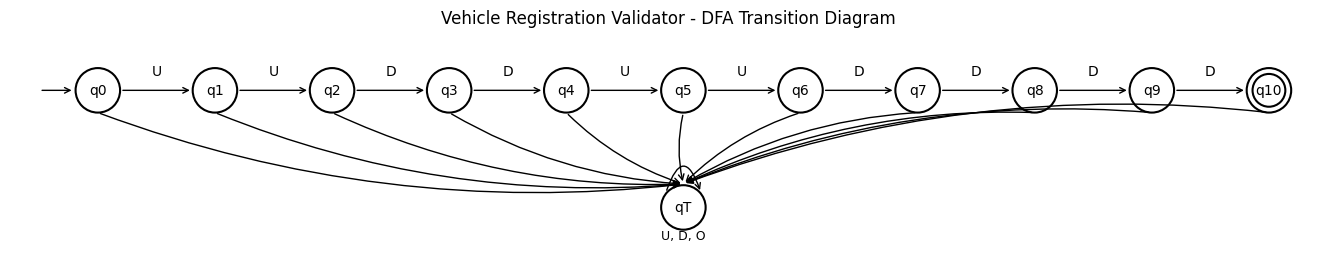

In [12]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(17, 4))

states = {
    "q0": (0, 2),
    "q1": (2, 2),
    "q2": (4, 2),
    "q3": (6, 2),
    "q4": (8, 2),
    "q5": (10, 2),
    "q6": (12, 2),
    "q7": (14, 2),
    "q8": (16, 2),
    "q9": (18, 2),
    "q10": (20, 2),
    "qT": (10, 0)
}

# Draw states
for state, (x, y) in states.items():
    if state == "q10":
        ax.add_patch(Circle((x, y), 0.38, fill=False, color="black", linewidth=1.5))
        ax.add_patch(Circle((x, y), 0.28, fill=False, color="black", linewidth=1.5))
    else:
        ax.add_patch(Circle((x, y), 0.38, fill=False, color="black", linewidth=1.5))

    ax.text(x, y, state, ha="center", va="center", fontsize=10)

# Initial arrow
ax.annotate("", xy=(-0.4, 2), xytext=(-1, 2),
            arrowprops=dict(arrowstyle="->", color="black"))

# Main transitions
labels = ["U", "U", "D", "D", "U", "U", "D", "D", "D", "D"]

for i in range(10):
    x1 = states[f"q{i}"][0] + 0.38
    x2 = states[f"q{i+1}"][0] - 0.38

    ax.annotate("", xy=(x2, 2), xytext=(x1, 2),
                arrowprops=dict(arrowstyle="->", color="black"))

    ax.text((x1+x2)/2, 2.25, labels[i],
            ha="center", fontsize=10)

# Invalid input transitions to trap state
for state in [f"q{i}" for i in range(11)]:
    x, y = states[state]

    ax.annotate("", xy=(10, 0.4), xytext=(x, y-0.38),
                arrowprops=dict(
                    arrowstyle="->",
                    color="black",
                    connectionstyle="arc3,rad=0.12"
                ))

# Trap state loop
ax.annotate("", xy=(10.3, 0.25), xytext=(9.7, 0.25),
            arrowprops=dict(
                arrowstyle="->",
                color="black",
                connectionstyle="arc3,rad=-1.5"
            ))

ax.text(10, -0.55, "U, D, O", ha="center", fontsize=9)

ax.set_xlim(-1.5, 21)
ax.set_ylim(-1, 3)
ax.set_aspect("equal")
ax.axis("off")

plt.title("Vehicle Registration Validator - DFA Transition Diagram")
plt.show()

In [13]:
import re

def vehicle_validator(number):
    pattern = r"^[A-Z]{2}[0-9]{2}[A-Z]{2}[0-9]{4}$"

    if re.fullmatch(pattern, number):
        return True
    else:
        return False


print("VEHICLE REGISTRATION VALIDATOR")
print("------------------------------")

number = input("Enter vehicle registration number: ")

if vehicle_validator(number):
    print("Accepted: Valid Registration Format")
else:
    print("Rejected: Invalid Registration Format")

VEHICLE REGISTRATION VALIDATOR
------------------------------
Enter vehicle registration number: TN23CD1234
Accepted: Valid Registration Format


In [14]:
vehicle_test_cases = [
    "TN09AB1234",
    "KL07CD5678",
    "KA01EF9876",
    "TN9AB1234",
    "TN09A12345",
    "tn09ab1234",
    "TN09AB12345",
    "TN@9AB1234"
]

print("VEHICLE REGISTRATION - TEST RESULTS")
print("-----------------------------------")

for number in vehicle_test_cases:
    if vehicle_validator(number):
        print(number, "-> Accepted")
    else:
        print(number, "-> Rejected")

VEHICLE REGISTRATION - TEST RESULTS
-----------------------------------
TN09AB1234 -> Accepted
KL07CD5678 -> Accepted
KA01EF9876 -> Accepted
TN9AB1234 -> Rejected
TN09A12345 -> Rejected
tn09ab1234 -> Rejected
TN09AB12345 -> Rejected
TN@9AB1234 -> Rejected


In [15]:
comparison_data = {
    "Application": [
        "Date Format Validator",
        "OTP Validator",
        "Vehicle Registration Validator"
    ],
    "Input Format": [
        "DD-MM-YYYY",
        "Exactly 6 digits",
        "LLDDLLDDDD"
    ],
    "Example": [
        "11-11-2026",
        "123456",
        "TN09AB1234"
    ],
    "Accepting State": [
        "q10",
        "q6",
        "q10"
    ],
    "Technique Used": [
        "DFA + Python Date Validation",
        "DFA + Regular Expression",
        "DFA + Regular Expression"
    ]
}

comparison_table = pd.DataFrame(comparison_data)

print("FINAL COMPARISON OF AUTOMATA APPLICATIONS")
display(comparison_table)

FINAL COMPARISON OF AUTOMATA APPLICATIONS


,Application,Input Format,Example,Accepting State,Technique Used
0,Date Format Validator,DD-MM-YYYY,11-11-2026,q10,DFA + Python Date Validation
1,OTP Validator,Exactly 6 digits,123456,q6,DFA + Regular Expression
2,Vehicle Registration Validator,LLDDLLDDDD,TN09AB1234,q10,DFA + Regular Expression


In [31]:
import os
import zipfile
from google.colab import files

folder = "/content/FLA_Automata_Project"
os.makedirs(folder, exist_ok=True)

# Collect existing diagram images without changing them
diagram_names = [
    "Date_DFA.png",
    "OTP_DFA.png",
    "Vehicle_DFA.png"
]

for name in diagram_names:
    source = "/content/" + name
    destination = os.path.join(folder, name)

    if os.path.exists(source):
        import shutil
        shutil.copy2(source, destination)

# Save transition tables
for name, data in [
    ("Date_Transition_Table.csv", date_transitions),
    ("OTP_Transition_Table.csv", otp_transitions),
    ("Vehicle_Transition_Table.csv", vehicle_transitions)
]:
    pd.DataFrame.from_dict(data, orient="index").to_csv(
        os.path.join(folder, name)
    )

# Save test cases
test_data = []

for app, cases, validator in [
    ("Date", date_test_cases, date_validator),
    ("OTP", otp_test_cases, otp_validator),
    ("Vehicle", vehicle_test_cases, vehicle_validator)
]:
    for value in cases:
        result = "Accepted" if validator(value) else "Rejected"
        test_data.append([app, value, result])

pd.DataFrame(
    test_data,
    columns=["Application", "Input", "Result"]
).to_csv(os.path.join(folder, "Test_Cases.csv"), index=False)

# Save README
with open(os.path.join(folder, "README.md"), "w") as f:
    f.write("""# FLA - Designing Automata for Real-Time Applications

## Applications
1. Date Format Validator (DD-MM-YYYY)
2. OTP Validator (Exactly 6 digits)
3. Vehicle Registration Validator (LLDDLLDDDD)

## Technologies
Python, DFA, Regular Expressions, Pandas, Matplotlib.

## Contents
Three DFA diagrams, transition tables, test cases and Python implementations.

Note: OTP and vehicle validators check formats only.
""")

# Save requirements
with open(os.path.join(folder, "requirements.txt"), "w") as f:
    f.write("pandas\nmatplotlib\n")

# Create ZIP
zip_path = "/content/FLA_Automata_Project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, filenames in os.walk(folder):
        for filename in filenames:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, folder))

print("Files included:")
for name in os.listdir(folder):
    print(name)

files.download(zip_path)

Files included:
Date_DFA.png
CLA2_Design_Note.md
OTP_DFA.png
validators.py
README.md
OTP_Transition_Table.csv
Date_Transition_Table.csv
Test_Cases.csv
Vehicle_DFA.png
requirements.txt
Vehicle_Transition_Table.csv
automata_test_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>